In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#                                PAINEL ESTATISTICO EM BIG DATA                       #

In [ ]:
import polars as pl


inicial = pl.scan_parquet("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\contratacao_localizar.parquet")

display(inicial)

In [ ]:
#               MÉTRICAS : MÉDIA, MEDIANA, MODA, VARIÂNCIA, E DESVIO PADRÃO, AMPLITUDE          #

In [ ]:
metricas1 = inicial.select([
    pl.col("Salarios").mean().alias("Média"),
    pl.col("Salarios").median().alias("Mediana"),
    # Moda retorna uma lista, pegamos o primeiro valor
    pl.col("Salarios").mode().first().alias("Moda"),
    pl.col("Salarios").var().alias("Variância"),
    pl.col("Salarios").std().alias("Desvio_Padrão"),
    (pl.col("Salarios").max() - pl.col("Salarios").min()).alias("Amplitude_Total")
]).collect()

#  Exibindo os resultados
print("\n--- Estatísticas Descritivas (Salários Localiza) ---")
display(metricas1)


--- Estatísticas Descritivas (Salários Localiza) ---


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude_Total
f64,f64,i64,f64,f64,i64
3678.267067,3450.0,1850,1.5317e6,1237.623378,4130


In [ ]:
#                         FORMA E POSIÇÃO: ASSÍMETRIA, CURTOSE E QUARTIS                 #

In [6]:


# Construindo a expressão de cálculo para a base Localiza
metricas2 = inicial.select([
    pl.col("Salarios").quantile(0.25).alias("Q1"),
    pl.col("Salarios").quantile(0.50).alias("Q2"),
    pl.col("Salarios").quantile(0.75).alias("Q3"),
    pl.col("Salarios").skew().alias("Assimetria"),
    pl.col("Salarios").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição (Salários Localiza) ---")
display(metricas2)

# Análise rápida da Assimetria
assimetria = metricas2["Assimetria"][0]
print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (Dados de salários bem balanceados)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Cauda para a direita - Existem salários muito altos puxando a média)")
else:
    print("-> Assimétrica Negativa (Cauda para a esquerda - Concentração maior em salários altos)")



--- Quartis e Forma da Distribuição (Salários Localiza) ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
2680.0,3450.0,4590.0,0.282219,-1.116624



Interpretação da Assimetria (0.28):
-> Distribuição Simétrica (Dados de salários bem balanceados)


In [ ]:
#                                      OUTLIERS                                    #

In [6]:

import polars as pl

# 1. Carrega os dados da sua tabela Localiza de forma direta (Eager mode)
df_localiza = pl.read_csv("contratacao_localizar.csv", separator=";")

# Padroniza os nomes das colunas para letras maiúsculas
df_localiza = df_localiza.rename({
    'Data de contratacao': 'DATA_CONTRATACAO',
    'Cargo': 'CARGO',
    'Salarios': 'SALARIOS',
    'Genero': 'GENERO'
})

# Garante que a coluna de salários seja numérica
df_localiza = df_localiza.with_columns(pl.col("SALARIOS").cast(pl.Float64))

# 2. Calcula matematicamente os Quartis e os Limites usando a sua coluna "SALARIOS"
q1 = df_localiza["SALARIOS"].quantile(0.25)
q3 = df_localiza["SALARIOS"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Diagnóstico Estatístico (Tabela Localiza) ---")
print(f"Limites Teóricos para Outliers: Inferior ({limite_inferior:.2f}) | Superior ({limite_superior:.2f})")

# 3. Filtra os Outliers Reais usando os limites calculados
outliers_reais = df_localiza.filter(
    (pl.col("SALARIOS") < limite_inferior) | (pl.col("SALARIOS") > limite_superior)
)

print(f"Quantidade de salários considerados Outliers Matemáticos: {outliers_reais.height}")

# 4. SOLUÇÃO DE NEGÓCIO: Se a matemática der 0 outliers, mostramos o teto e o piso reais da empresa
if outliers_reais.height == 0:
    print("\n💡 Insights de RH: Como não existem outliers no papel, isolamos o Topo e a Base reais da folha:")
    
    # Pega os maiores salários da empresa (Top 5)
    topo_folha = df_localiza.sort("SALARIOS", descending=True).head(5)
    print("\n[TOPO] Maiores salários de admissão registrados:")
    display(topo_folha.select(["CARGO", "GENERO", "SALARIOS"]))
    
    # Pega os menores salários da empresa (Piso 5)
    piso_folha = df_localiza.sort("SALARIOS").head(5)
    print("\n[BASE] Menores salários de admissão registrados:")
    display(piso_folha.select(["CARGO", "GENERO", "SALARIOS"]))
else:
    print("\nExemplos de valores discrepantes encontrados:")
    display(outliers_reais.select(["CARGO", "GENERO", "SALARIOS"]).head())


--- Diagnóstico Estatístico (Tabela Localiza) ---
Limites Teóricos para Outliers: Inferior (-185.00) | Superior (7455.00)
Quantidade de salários considerados Outliers Matemáticos: 0

💡 Insights de RH: Como não existem outliers no papel, isolamos o Topo e a Base reais da folha:

[TOPO] Maiores salários de admissão registrados:


CARGO,GENERO,SALARIOS
str,str,f64
null,null,null
"""Analista Financeiro""","""Masculino""",5980.0
"""Assistente Administrativo""","""Feminino""",5980.0
"""Consultor(a) de Negócios""","""Feminino""",5980.0
"""Gerente Comercial""","""Masculino""",5980.0



[BASE] Menores salários de admissão registrados:


CARGO,GENERO,SALARIOS
str,str,f64
null,null,null
"""Atendente de Relacionamento""","""Feminino""",1850.0
"""Atendente de Relacionamento""","""Masculino""",1850.0
"""Analista Financeiro""","""Feminino""",1850.0
"""Supervisor(a) de Logística""","""Masculino""",1850.0


In [ ]:
#                                                    VISUALIZAÇÃO                                 #

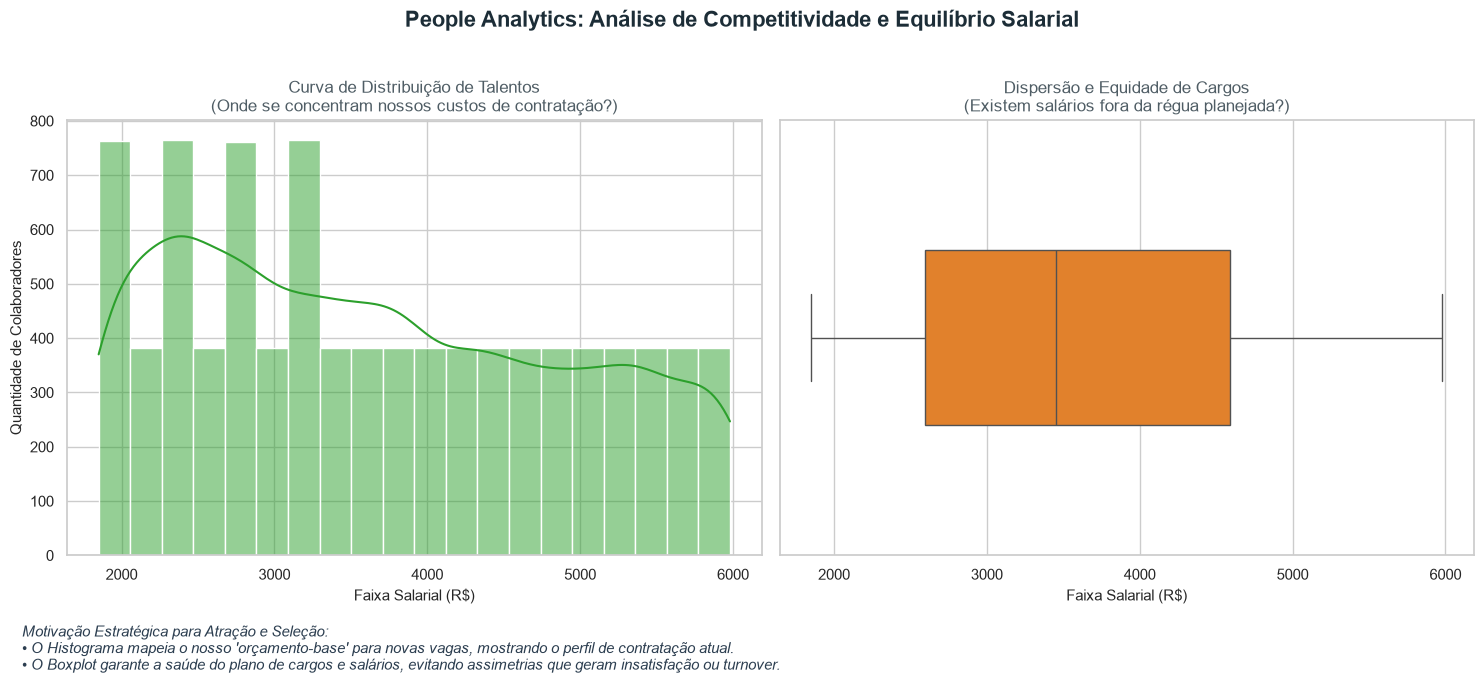

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Definindo um estilo visual mais limpo e profissional
sns.set_theme(style="whitegrid")

# Extraindo os dados de Salários
visual = inicial.select("Salarios").collect().to_series()

# Criando a figura com espaço para um supertítulo e notas de rodapé
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Título Principal focado em Inteligência de Negócio (People Analytics)
plt.suptitle(
    "People Analytics: Análise de Competitividade e Equilíbrio Salarial", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# 1. Histograma: Motivação - Desenhar a curva de atração do mercado
sns.histplot(visual, bins=20, kde=True, color='#2ca02c', ax=axes[0])
axes[0].set_title('Curva de Distribuição de Talentos\n(Onde se concentram nossos custos de contratação?)', fontsize=12, color='#4f5d65')
axes[0].set_xlabel('Faixa Salarial (R$)', fontsize=11)
axes[0].set_ylabel('Quantidade de Colaboradores', fontsize=11)

# 2. Boxplot: Motivação - Identificar distorções e planejar cargos/salários
sns.boxplot(x=visual, color='#ff7f0e', ax=axes[1], width=0.4)
axes[1].set_title('Dispersão e Equidade de Cargos\n(Existem salários fora da régua planejada?)', fontsize=12, color='#4f5d65')
axes[1].set_xlabel('Faixa Salarial (R$)', fontsize=11)

# Adicionando uma nota de motivação estratégica no rodapé do gráfico
motivacao_texto = (
    "Motivação Estratégica para Atração e Seleção:\n"
    "• O Histograma mapeia o nosso 'orçamento-base' para novas vagas, mostrando o perfil de contratação atual.\n"
    "• O Boxplot garante a saúde do plano de cargos e salários, evitando assimetrias que geram insatisfação ou turnover."
)
plt.figtext(0.02, -0.08, motivacao_texto, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()



In [ ]:
#                                                                         RECORTE DO HISTOGRAMA                          #

c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


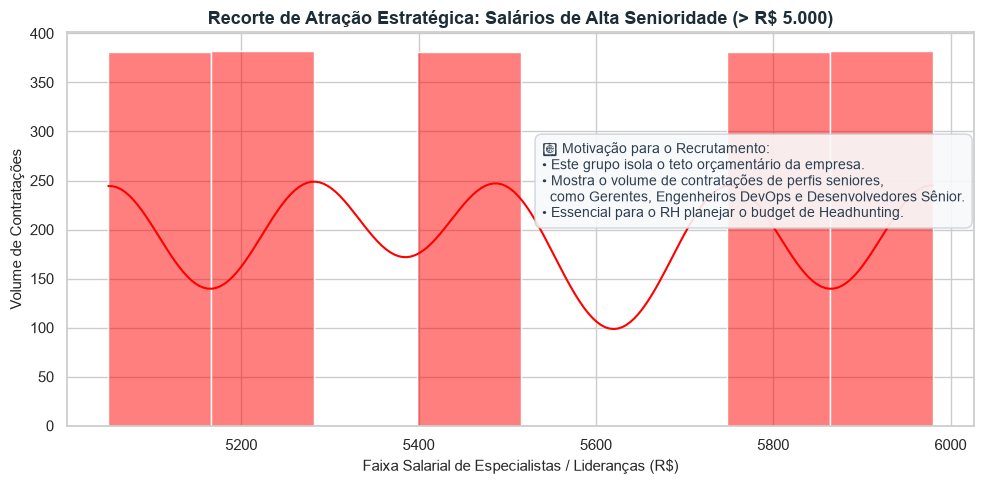

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Filtrar os salários de alta senioridade (> R$ 5.000) de acordo com a base Localiza
visual_superiores = inicial.filter(
    pl.col("Salarios") > 5000
).select("Salarios").collect().to_series()

plt.figure(figsize=(10, 5))

# 2. Gerar o histograma de alta senioridade com foco em Recrutamento
sns.histplot(visual_superiores, kde=True, color='red', bins=8)

# Títulos e legendas motivacionais focadas em Contratação
plt.title('Recorte de Atração Estratégica: Salários de Alta Senioridade (> R$ 5.000)', fontsize=13, fontweight='bold', color='#1c2d37')
plt.xlabel('Faixa Salarial de Especialistas / Lideranças (R$)', fontsize=11)
plt.ylabel('Volume de Contratações', fontsize=11)

# Caixa de texto explicativa (People Analytics) diretamente no gráfico
texto_insights = (
    "🎯 Motivação para o Recrutamento:\n"
    "• Este grupo isola o teto orçamentário da empresa.\n"
    "• Mostra o volume de contratações de perfis seniores,\n"
    "  como Gerentes, Engenheiros DevOps e Desenvolvedores Sênior.\n"
    "• Essencial para o RH planejar o budget de Headhunting."
)
plt.figtext(0.55, 0.55, texto_insights, fontsize=10, color='#2c3e50',
            bbox=dict(facecolor='#f8f9fa', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()


In [ ]:
#                                           CORRELAÇÃO DE PEARSON                        #

In [13]:
import polars as pl

# 1. Criar o DataFrame Agregado por Cargo (Agrupando os dados da Localiza)
df_cargos = inicial.group_by("Cargo").agg([
    pl.len().alias("Qtd_Contratacoes"),  # Quantidade de funcionários no cargo (Variável X)
    pl.col("Salarios").mean().alias("Salario_Medio") # Salário médio do cargo (Variável Y)
])

# 2. Calcular a Correlação de Pearson entre Volume de Vagas e Salário Médio
correlacao = df_cargos.select(
    pl.corr("Qtd_Contratacoes", "Salario_Medio", method="pearson").alias("r")
).collect()

r = correlacao["r"][0]
r2 = r**2

print(f"--- Análise de Correlação Estratégica (Recrutamento Localiza) ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}\n")

# 3. Interpretação e Motivação para o RH
if abs(r) < 0.3:
    print("Conclusão: Correlação FRACA.")
    print("-> Motivação de RH: O volume de contratações é independente do salário. O RH contrata de forma equilibrada tanto cargos operacionais quanto posições mais caras, sem que a folha seja inflacionada por um único cargo de alto volume.")
elif r < -0.3:
    print("Conclusão: Correlação NEGATIVA.")
    print("-> Motivação de RH: Estrutura piramidal clássica. Os cargos com maior volume de contratações possuem os menores salários médios (ex: Atendentes), o que mantém o custo geral da folha sob controle.")
else:
    print("Conclusão: Correlação POSITIVA.")
    print("-> Motivação de RH: Alerta de Custo. Os cargos mais contratados também são os que possuem os salários mais altos, indicando que a empresa está investindo pesado e competindo agressivamente por talentos caros (ex: Tecnologia/Especialistas).")


--- Análise de Correlação Estratégica (Recrutamento Localiza) ---
Coeficiente de Pearson (r): -0.4107
Coeficiente de Determinação (r²): 0.1687

Conclusão: Correlação NEGATIVA.
-> Motivação de RH: Estrutura piramidal clássica. Os cargos com maior volume de contratações possuem os menores salários médios (ex: Atendentes), o que mantém o custo geral da folha sob controle.


In [ ]:
#                                                     GRAFICO DE DISPERSÃO                             #

c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


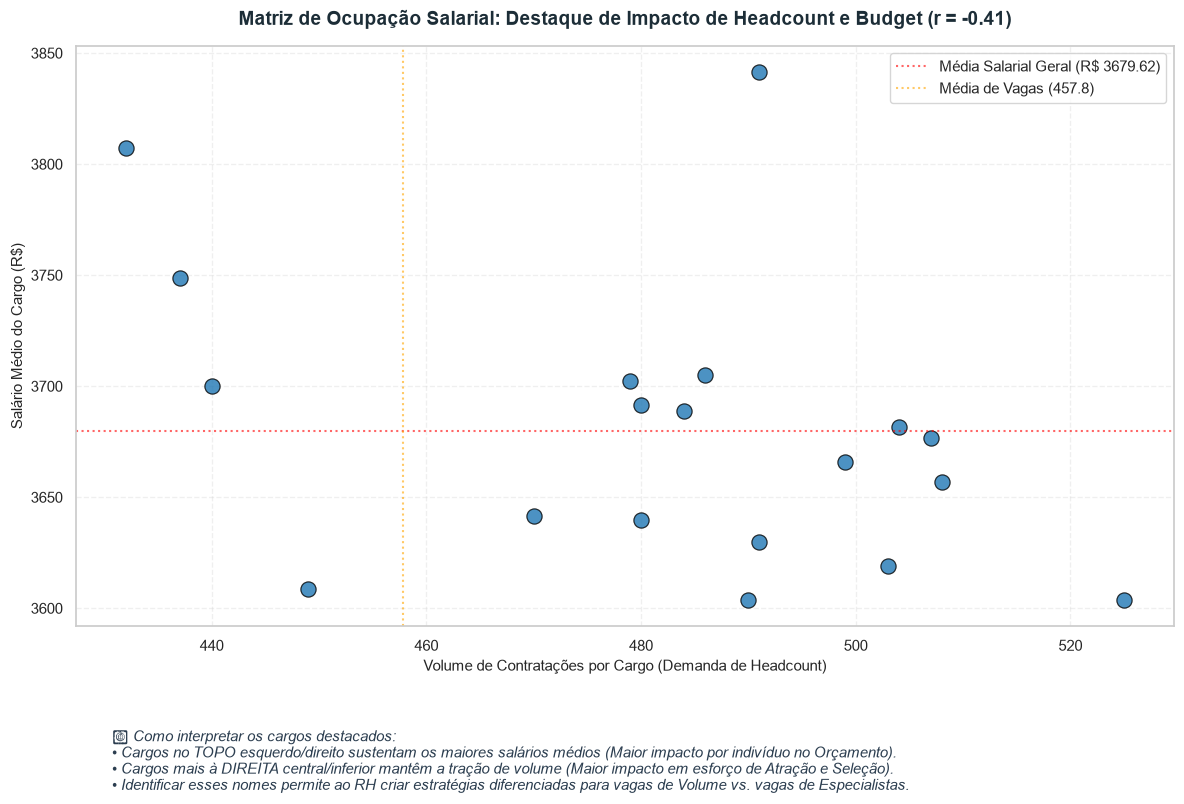

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Coletando e ordenando os dados agregados dos cargos
df_scatter = df_cargos.collect()
df_pandas = df_scatter.to_pandas()

plt.figure(figsize=(12, 7))

# 2. Criando o Gráfico de Dispersão
sns.scatterplot(
    data=df_pandas,
    x="Qtd_Contratacoes",
    y="Salario_Medio",
    s=120, 
    color='#1f77b4',
    alpha=0.8,
    edgecolor='black'
)

# 3. DESTACANDO OS CARGOS (Anotações automáticas no gráfico)
# Vamos varrer os cargos e colocar o nome daqueles que chamam atenção em custo ou volume
for i in range(df_pandas.shape[0]):
    cargo = df_pandas.iloc[i]['Cargo']
    x = df_pandas.iloc[i]['Qtd_Contratacoes']
    y = df_pandas.iloc[i]['Salario_Medio']
    
    # Condição para destacar: Se o cargo tiver MUITA contratação OU salário MUITO alto
    # Isso evita poluir o gráfico com texto em todos os pontos, focando no que importa
    if x > df_pandas['Qtd_Contratacoes'].mean() * 1.2 or y > df_pandas['Salario_Medio'].mean() * 1.2:
        plt.text(
            x + 0.2, y + 50, s=cargo, 
            fontsize=9, fontweight='bold', color='#2c3e50',
            bbox=dict(facecolor='#f8f9fa', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
        )

# Títulos e Legendas focados em Inteligência de Recrutamento (People Analytics)
plt.title(f'Matriz de Ocupação Salarial: Destaque de Impacto de Headcount e Budget (r = {r:.2f})', fontsize=14, fontweight='bold', color='#1c2d37', pad=15)
plt.xlabel('Volume de Contratações por Cargo (Demanda de Headcount)', fontsize=11)
plt.ylabel('Salário Médio do Cargo (R$)', fontsize=11)
plt.grid(True, alpha=0.3, linestyle='--')

# Adicionando linhas de referência (médias gerais) para criar os quadrantes estratégicos
media_salarial = df_pandas["Salario_Medio"].mean()
media_contratacoes = df_pandas["Qtd_Contratacoes"].mean()

plt.axhline(media_salarial, color='red', linestyle=':', alpha=0.6, label=f'Média Salarial Geral (R$ {media_salarial:.2f})')
plt.axvline(media_contratacoes, color='orange', linestyle=':', alpha=0.6, label=f'Média de Vagas ({media_contratacoes:.1f})')
plt.legend(loc='upper right')

# Texto motivacional focado em Planejamento Estratégico de Contratação
texto_motivacao = (
    "💡 Como interpretar os cargos destacados:\n"
    "• Cargos no TOPO esquerdo/direito sustentam os maiores salários médios (Maior impacto por indivíduo no Orçamento).\n"
    "• Cargos mais à DIREITA central/inferior mantêm a tração de volume (Maior impacto em esforço de Atração e Seleção).\n"
    "• Identificar esses nomes permite ao RH criar estratégias diferenciadas para vagas de Volume vs. vagas de Especialistas."
)
plt.figtext(0.10, -0.14, s=texto_motivacao, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [ ]:
#                               CORRELAÇÕES  DE PEARSON E  SPEARMAN                         #

In [17]:
import polars as pl

# 1. Executando o cálculo das correlações de Pearson e Spearman no agregado de cargos
analise_correlacao = df_cargos.select([
    pl.corr("Qtd_Contratacoes", "Salario_Medio", method="pearson").alias("Pearson"),
    pl.corr("Qtd_Contratacoes", "Salario_Medio", method="spearman").alias("Spearman")
]).collect()

print("\n--- Coeficientes de Correlação (Recrutamento Localiza) ---")
print(analise_correlacao)

# 2. Extraindo os valores para interpretação
r_pearson = analise_correlacao["Pearson"][0]
r_spearman = analise_correlacao["Spearman"][0]

print(f"\n💡 Motivação de People Analytics para o RH:")
print(f"• Pearson ({r_pearson:.4f}): Avalia se a relação de crescimento entre volume e salário é linear (em linha reta).")
print(f"• Spearman ({r_spearman:.4f}): Avalia a relação de postos/rankings (se cargos mais frequentes tendem a estar sempre no topo ou fundo da tabela salarial).")



--- Coeficientes de Correlação (Recrutamento Localiza) ---
shape: (1, 2)
┌──────────┬───────────┐
│ Pearson  ┆ Spearman  │
│ ---      ┆ ---       │
│ f64      ┆ f64       │
╞══════════╪═══════════╡
│ -0.41074 ┆ -0.424056 │
└──────────┴───────────┘

💡 Motivação de People Analytics para o RH:
• Pearson (-0.4107): Avalia se a relação de crescimento entre volume e salário é linear (em linha reta).
• Spearman (-0.4241): Avalia a relação de postos/rankings (se cargos mais frequentes tendem a estar sempre no topo ou fundo da tabela salarial).


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


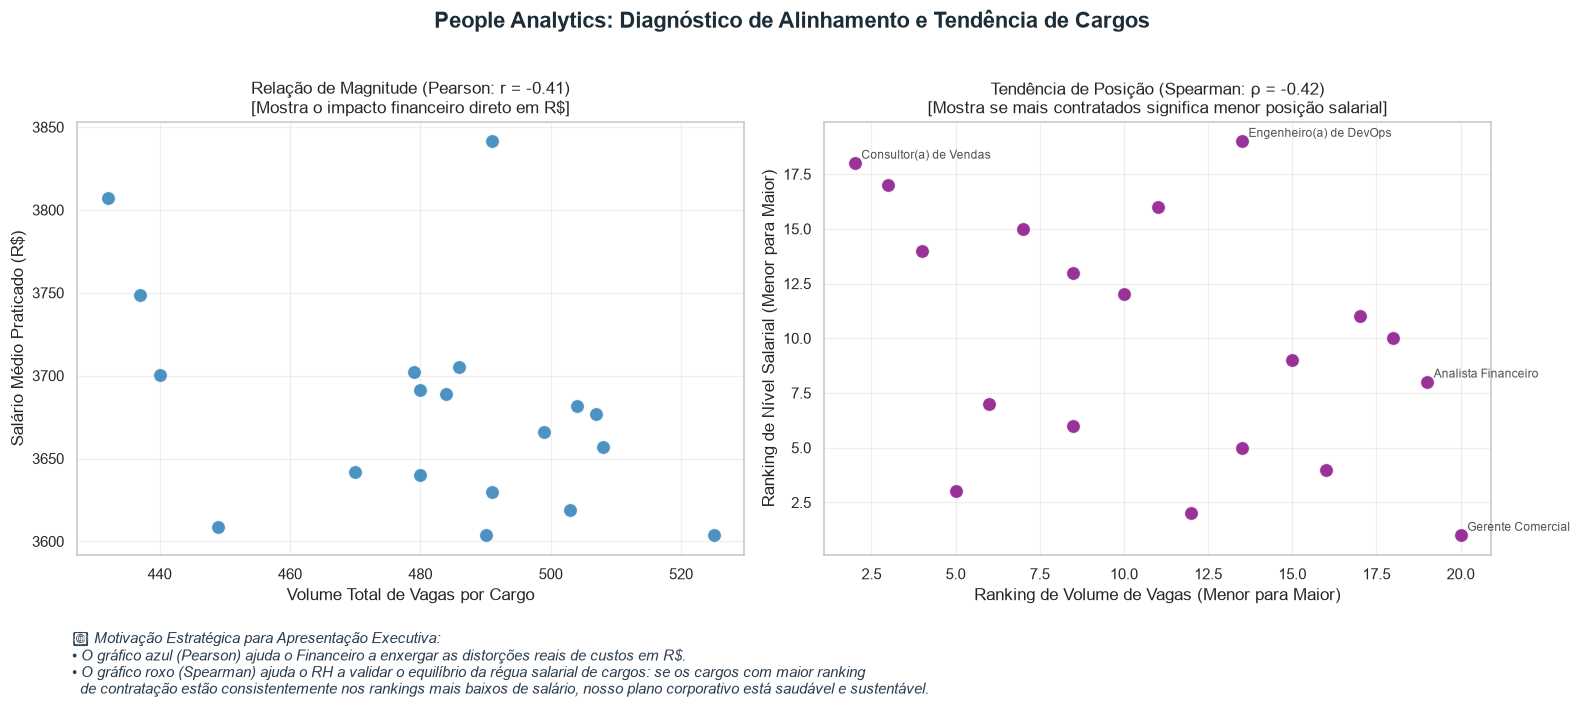

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Preparar os dados de Contratação Localiza com os Rankings (Spearman)
df_spearman = df_cargos.with_columns([
    pl.col("Qtd_Contratacoes").rank().alias("Rank_Qtd"),
    pl.col("Salario_Medio").rank().alias("Rank_Salario")
]).collect()

df_pandas = df_spearman.to_pandas()

# 2. Plotar Comparativo de People Analytics: Dados Brutos vs. Ranks
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.suptitle(
    "People Analytics: Diagnóstico de Alinhamento e Tendência de Cargos", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# --- Gráfico 1: Dados Brutos (Visão Pearson) ---
sns.scatterplot(
    data=df_pandas,
    x="Qtd_Contratacoes",
    y="Salario_Medio",
    ax=axes[0],
    s=100,
    color='#1f77b4',
    alpha=0.8
)
axes[0].set_title(f'Relação de Magnitude (Pearson: r = {r_pearson:.2f})\n[Mostra o impacto financeiro direto em R$]', fontsize=12)
axes[0].set_xlabel('Volume Total de Vagas por Cargo')
axes[0].set_ylabel('Salário Médio Praticado (R$)')
axes[0].grid(True, alpha=0.3)

# Rótulo nos pontos extremos do Gráfico 1 (Maiores salários e maiores volumes)
for idx, row in df_pandas.iterrows():
    if row['Salario_Medio'] > df_pandas['Salario_Medio'].mean() * 1.2 or row['Qtd_Contratacoes'] > df_pandas['Qtd_Contratacoes'].mean() * 1.3:
        axes[0].text(row['Qtd_Contratacoes'] + 0.2, row['Salario_Medio'] + 30, row['Cargo'], fontsize=8.5, alpha=0.8)


# --- Gráfico 2: Dados de Ranking (Visão Spearman) ---
sns.scatterplot(
    data=df_pandas,
    x="Rank_Qtd",
    y="Rank_Salario",
    ax=axes[1],
    s=100,
    color='purple',
    alpha=0.8
)
axes[1].set_title(f'Tendência de Posição (Spearman: ρ = {r_spearman:.2f})\n[Mostra se mais contratados significa menor posição salarial]', fontsize=12)
axes[1].set_xlabel('Ranking de Volume de Vagas (Menor para Maior)')
axes[1].set_ylabel('Ranking de Nível Salarial (Menor para Maior)')
axes[1].grid(True, alpha=0.3)

# Rótulo nos pontos de topo do Gráfico 2 (Maiores posições no ranking)
for idx, row in df_pandas.iterrows():
    if row['Rank_Salario'] > df_pandas['Rank_Salario'].max() - 2 or row['Rank_Qtd'] > df_pandas['Rank_Qtd'].max() - 2:
        axes[1].text(row['Rank_Qtd'] + 0.2, row['Rank_Salario'] + 0.2, row['Cargo'], fontsize=8.5, alpha=0.8)


# Texto de rodapé motivacional para tomada de decisão estratégica em contratação
texto_explicativo = (
    "💡 Motivação Estratégica para Apresentação Executiva:\n"
    "• O gráfico azul (Pearson) ajuda o Financeiro a enxergar as distorções reais de custos em R$.\n"
    "• O gráfico roxo (Spearman) ajuda o RH a validar o equilíbrio da régua salarial de cargos: se os cargos com maior ranking\n"
    "  de contratação estão consistentemente nos rankings mais baixos de salário, nosso plano corporativo está saudável e sustentável."
)
plt.figtext(0.05, -0.12, s=texto_explicativo, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import polars as pl
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [ ]:
#                                               REGRESSÃO LINEAR E FUNDAMENTOS DE  ANÁLISE  PREDITIVA                 #

In [20]:
import polars as pl

# 1. Carregando a base Localiza em modo Lazy (Lendo o CSV)
inicial = (
    pl.scan_csv("contratacao_localizar.csv", separator=";")
    
    # 2. Padronizando os nomes das colunas (Removendo espaços e acentos)
    .rename({
        'Data de contratacao': 'DATA_CONTRATACAO',
        'Cargo': 'CARGO',
        'Salarios': 'SALARIOS',
        'Genero': 'GENERO'
    })
    
    # 3. Garantindo que a coluna de Salários seja tratada como float/numérica
    .with_columns(
        pl.col("SALARIOS").cast(pl.Float64)
    )
    
    # 4. Tratando a string de data e transformando em um tipo Date real (padrão YYYY-MM-DD)
    .with_columns(
        pl.col("DATA_CONTRATACAO")
        .str.strptime(pl.Date, format="%d/%m/%Y")
        .alias("DATA_CONTRATACAO_REF")
    )
)

# 5. Executando o pipeline e exibindo o DataFrame final limpo
display(inicial.collect())


GENERO,DATA_CONTRATACAO,CARGO,SALARIOS,DATA_CONTRATACAO_REF
str,str,str,f64,date
"""Masculino""","""14/12/2025""","""Analista Financeiro""",5980.0,2025-12-14
"""Feminino""","""21/10/2025""","""Desenvolvedor(a) Software""",2280.0,2025-10-21
"""Masculino""","""26/02/2025""","""Gerente de Operações""",5280.0,2025-02-26
"""Feminino""","""10/07/2025""","""Atendente de Relacionamento""",3280.0,2025-07-10
"""Feminino""","""01/11/2025""","""Atendente de Relacionamento""",1850.0,2025-11-01
…,…,…,…,…
"""Feminino""","""13/07/2025""","""Assistente Administrativo""",4180.0,2025-07-13
"""Masculino""","""12/12/2025""","""Desenvolvedor(a) Software""",3950.0,2025-12-12
"""Masculino""","""10/06/2025""","""Consultor(a) de Negócios""",2390.0,2025-06-10


In [ ]:
#                                                 DADOS PARA PLOTAGEM                                       #

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Agrupar os dados por Mês de Contratação e calcular a Média Salarial
df_agrupado = (
    inicial
    # CORREÇÃO CRÍTICA: Ordenar as datas ANTES de usar o group_by_dynamic
    .sort("DATA_CONTRATACAO_REF")
    .group_by_dynamic("DATA_CONTRATACAO_REF", every="1mo")
    .agg(
        pl.col("SALARIOS").mean().alias("SALARIO_MEDIO")
    )
    .collect()
)

# 2. Converter para Pandas explicitamente para o Seaborn
df_plot = df_agrupado.to_pandas()

# Verificar os dados que serão plotados no terminal
print("Evolução Mensal da Folha de Contratação:")
print(df_plot.head())

# 3. Configurar o estilo do seaborn
sns.set_theme(style="whitegrid")

# Criar a figura e o eixo explicitamente
fig, ax = plt.subplots(figsize=(12, 6))

# Plotar a linha do tempo usando o seaborn
sns.lineplot(
    data=df_plot,
    x="DATA_CONTRATACAO_REF",
    y="SALARIO_MEDIO",
    ax=ax,          
    marker='o',     
    linewidth=2.5,  
    color='#2ca02c' 
)

# Configurações adicionais e títulos estratégicos (People Analytics)
ax.set_title("Evolução do Salário Médio de Admissão ao Longo do Tempo (2025)", fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel("Mês de Contratação", labelpad=10, fontsize=11)
ax.set_ylabel("Salário Médio de Entrada (R$)", labelpad=10, fontsize=11)
ax.tick_params(axis='x', rotation=45)  

# Nota motivacional de planejamento orçamentário no gráfico
texto_rh = (
    "💡 Motivação Estratégica (Budget & Turnover):\n"
    "Este gráfico monitora se o custo de aquisição de talentos está subindo ao longo do ano.\n"
    "Picos na linha indicam meses onde contratamos profissionais mais seniores ou técnicos (ex: especialistas),\n"
    "enquanto quedas indicam períodos de contratação em massa de perfis operacionais."
)

# Ajuste fino na posição do texto para não cortar dependendo do ambiente
plt.figtext(0.1, -0.15, s=texto_rh, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


NameError: name 'inicial' is not defined

In [ ]:
#                                    PREPARAÇÃO DOS DADOS PARA REGRESSÃO LINEAR                          #

In [23]:
import polars as pl

# 1. Garantir que a coluna temporal esteja no tipo Date do Polars
if df_agrupado["DATA_CONTRATACAO_REF"].dtype != pl.Date:
    df_agrupado = df_agrupado.with_columns(
        pl.col("DATA_CONTRATACAO_REF").cast(pl.Date)
    )

# 2. Calcular o tempo decorrido em meses usando expressões puras do Polars
# (Transforma as datas do ano de 2025 em uma sequência numérica de 0, 1, 2, 3...)
df_reg = df_agrupado.with_columns(
    (pl.col("DATA_CONTRATACAO_REF").dt.year() * 12 + pl.col("DATA_CONTRATACAO_REF").dt.month() - 
     (pl.col("DATA_CONTRATACAO_REF").min().dt.year() * 12 + pl.col("DATA_CONTRATACAO_REF").min().dt.month()))
    .alias("MESES_DESDE_INICIO")
)

# 3. Verificar o resultado na tela
print("--- Linha do Tempo Indexada por Meses (Recrutamento Localiza) ---")
print(df_reg.select(["DATA_CONTRATACAO_REF", "SALARIO_MEDIO", "MESES_DESDE_INICIO"]).head())


--- Linha do Tempo Indexada por Meses (Recrutamento Localiza) ---
shape: (5, 3)
┌──────────────────────┬───────────────┬────────────────────┐
│ DATA_CONTRATACAO_REF ┆ SALARIO_MEDIO ┆ MESES_DESDE_INICIO │
│ ---                  ┆ ---           ┆ ---                │
│ date                 ┆ f64           ┆ i32                │
╞══════════════════════╪═══════════════╪════════════════════╡
│ 2025-01-01           ┆ 3701.561315   ┆ 0                  │
│ 2025-02-01           ┆ 3697.005988   ┆ 1                  │
│ 2025-03-01           ┆ 3635.946124   ┆ 2                  │
│ 2025-04-01           ┆ 3711.423027   ┆ 3                  │
│ 2025-05-01           ┆ 3645.459921   ┆ 4                  │
└──────────────────────┴───────────────┴────────────────────┘


--- Modelo de Tendência Salarial (Recrutamento Localiza) ---
Equação da reta: SALARIO_MEDIO = -1.48 * MESES_DESDE_INICIO + 3686.84
Coeficiente angular (Ritmo de variação R$/mês): R$ -1.48
Intercepto (Salário base inicial estimado): R$ 3686.84

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.0195
Erro Quadrático Médio (MSE): 1321.11


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


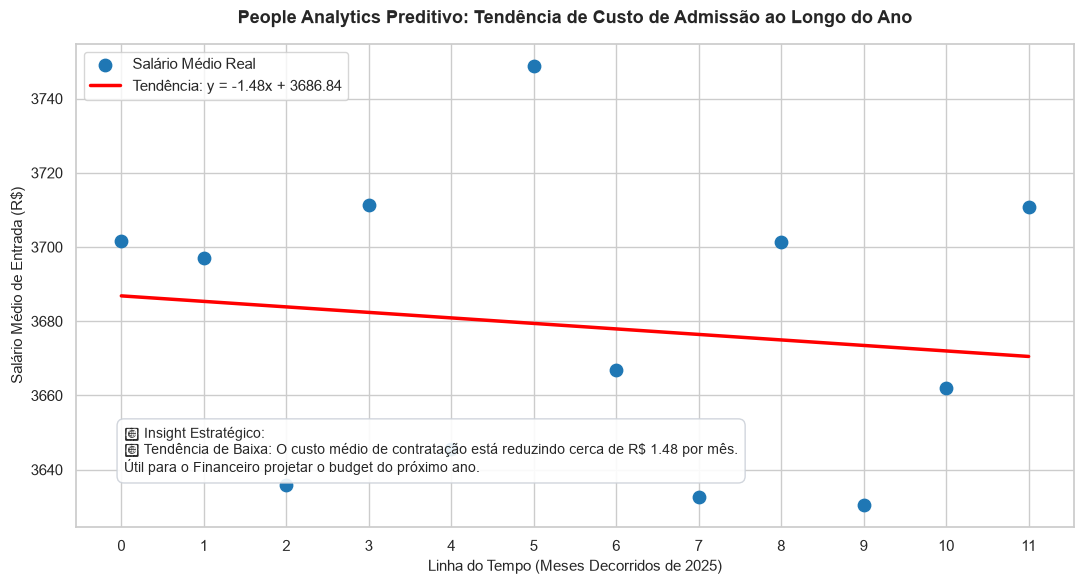

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import numpy as np
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import r2_score, mean_squared_error

## 1. Preparar os dados para o modelo Localiza
# Converter as colunas do Polars para arrays numpy
X = df_reg["MESES_DESDE_INICIO"].to_numpy().reshape(-1, 1)  # Variável independente (Tempo em meses)
y = df_reg["SALARIO_MEDIO"].to_numpy()                      # Variável dependente (Salário de admissão)

## 2. Criar e treinar o modelo preditivo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"--- Modelo de Tendência Salarial (Recrutamento Localiza) ---")
print(f"Equação da reta: SALARIO_MEDIO = {inclinacao:.2f} * MESES_DESDE_INICIO + {intercepto:.2f}")
print(f"Coeficiente angular (Ritmo de variação R$/mês): R$ {inclinacao:.2f}")
print(f"Intercepto (Salário base inicial estimado): R$ {intercepto:.2f}")

## 3. Fazer as previsões para a linha de tendência
y_pred = modelo.predict(X)

## 4. Avaliar a precisão do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

## 5. Visualização Gráfica da Tendência de Orçamento
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das médias mensais
plt.scatter(X, y, color='#1f77b4', s=80, label='Salário Médio Real', zorder=5)

# Plotar a linha vermelha de regressão (tendência de mercado)
plt.plot(X, y_pred, color='red', linewidth=2.5, label=f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}')

# Configurações do gráfico voltadas para RH e Finanças
plt.title('People Analytics Preditivo: Tendência de Custo de Admissão ao Longo do Ano', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos de 2025)', fontsize=11)
plt.ylabel('Salário Médio de Entrada (R$)', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Garante passos de 1 em 1 mês no eixo X

# Nota de interpretação corporativa
if inclinacao > 0:
    interpretacao_texto = f"📈 Tendência de Alta: O custo médio de contratação está subindo cerca de R$ {inclinacao:.2f} por mês."
else:
    interpretacao_texto = f"📉 Tendência de Baixa: O custo médio de contratação está reduzindo cerca de R$ {abs(inclinacao):.2f} por mês."

plt.figtext(0.12, 0.20, s=f"💡 Insight Estratégico:\n{interpretacao_texto}\nÚtil para o Financeiro projetar o budget do próximo ano.", 
            fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


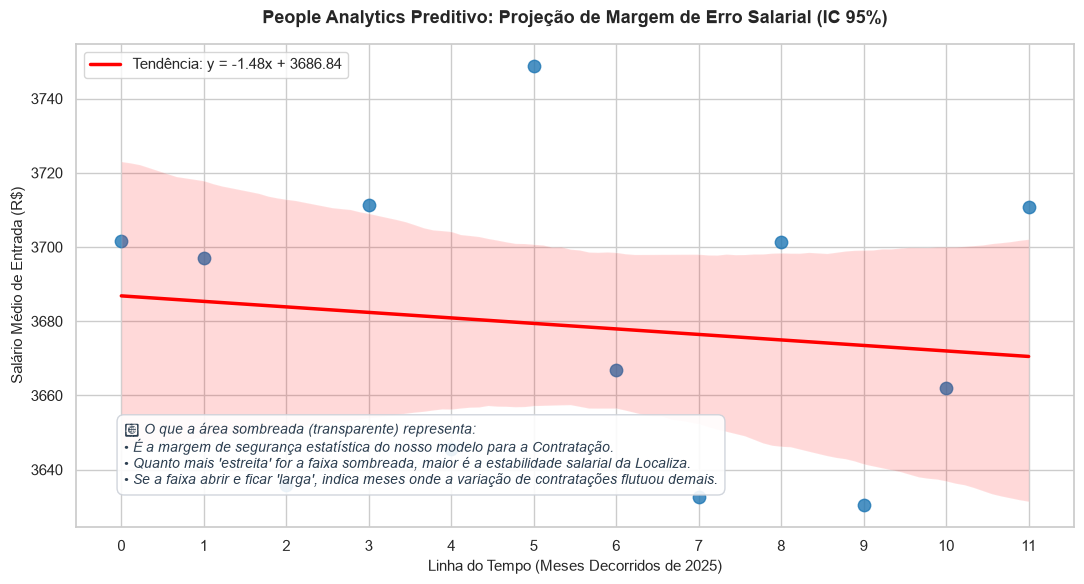

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Gerando o gráfico de regressão com intervalo de confiança (ci=95)
# .flatten() transforma a matriz X de volta em uma lista simples para o Seaborn
sns.regplot(
    x=X.flatten(), 
    y=y, 
    ci=95, 
    scatter_kws={'color': '#1f77b4', 's': 80, 'label': 'Salário Médio Real'},
    line_kws={'color': 'red', 'linewidth': 2.5, 'label': f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}'}
)

# Títulos e legendas estratégicas (People Analytics)
plt.title('People Analytics Preditivo: Projeção de Margem de Erro Salarial (IC 95%)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos de 2025)', fontsize=11)
plt.ylabel('Salário Médio de Entrada (R$)', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Garante passos de 1 em 1 mês no eixo X

# Nota explicativa sobre a área sombreada (Intervalo de Confiança)
texto_rh = (
    "💡 O que a área sombreada (transparente) representa:\n"
    "• É a margem de segurança estatística do nosso modelo para a Contratação.\n"
    "• Quanto mais 'estreita' for a faixa sombreada, maior é a estabilidade salarial da Localiza.\n"
    "• Se a faixa abrir e ficar 'larga', indica meses onde a variação de contratações flutuou demais."
)
plt.figtext(0.12, 0.18, s=texto_rh, fontsize=10, color='#2c3e50', style='italic',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
